Turning sources to the strain observed at a detector

In [4]:
import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
from jimgw.core.single_event.detector import get_H1, get_L1
import ripplegw
import matplotlib.pyplot as plt

In [5]:
frequency = jnp.arange(20.0, 1024.0, 0.25)
df = 0.25
N = 8192
dt = 1/2048

time = (jnp.arange(N) - N/2) * dt
time = jnp.arange(N) * dt


full_frequency = jnp.arange(0, 1024.25, df)

def h_to_htime_shift(h, df, N, shift: float = 0, noise = None, shift_to_time: bool = True):
    h_full = jnp.pad(h, (80,1))
    h_shifted_f = h_full * jnp.exp(-2j * jnp.pi * full_frequency * shift)

    if noise is not None:
        h_shifted_f = h_shifted_f + noise
        
    if shift_to_time:
        return jnp.fft.irfft(h_shifted_f, n=N) * (N * df)

    return h_shifted_f

params = {
"M_c": 50,   # chirp mass [solar masses]
"eta": 0.247,  # symmetric mass ratio
"s1_z": 0.0,   # primary aligned spin
"s2_z": 0.0,   # secondary aligned spin
"d_L": 400,  # luminosity distance [Mpc]
"phase_c": 0.0,
"iota": jnp.pi/3,
}

waveform = ripplegw.waveform("IMRPhenomD", f_ref=20)
polarizations = waveform(frequency, params)

hp = polarizations["p"]
hc = polarizations["c"]

L1 = get_L1()
H1 = get_H1()


In [6]:
source_params = {"ra" : 1.0, "dec" : 0.5, "psi" : 0.0, "gmst" : 0.0}
list(source_params.values())

[1.0, 0.5, 0.0, 0.0]

In [7]:
source_params = {"ra" : 1.0, "dec" : 0.5, "psi" : 0.0, "gmst" : 0.0}

F_H1 = H1.antenna_pattern(*source_params.values())
F_L1 = L1.antenna_pattern(*source_params.values())

#get how signal will look at detectors at H1 and L1
h_H1 = F_H1["p"] * hp + F_H1["c"] * hc
h_L1 = F_L1["p"] * hp + F_L1["c"] * hc

Plotting observed strain

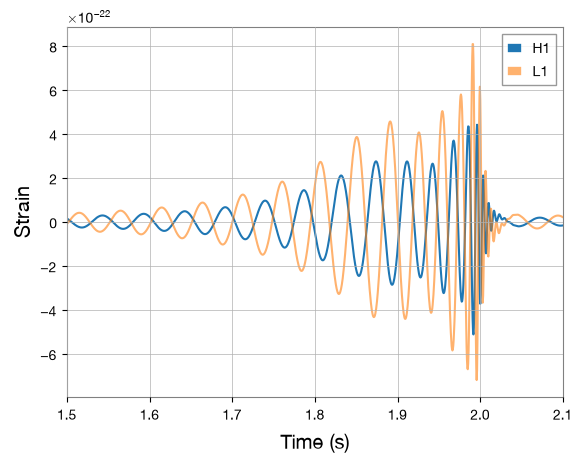

In [8]:
h_H1_time = h_to_htime_shift(h_H1, df, N, shift=2)
h_L1_time = h_to_htime_shift(h_L1, df, N, shift=2)

plt.plot(time, h_H1_time, label="H1")
plt.plot(time, h_L1_time, label="L1", alpha = 0.6)
plt.xlabel("Time (s)")
plt.ylabel("Strain")
plt.xlim(1.5, 2.1)
plt.legend()
plt.show()

Need a time delay based on location, but not major factor for now, need some time in the data?  

Now adding noise, using PSD's of H1 and L1

INFO | jimgw.core.single_event.detector | Loading the design-sensitivity ASD for H1
INFO | jimgw.core.single_event.detector | Loading the design-sensitivity ASD for L1


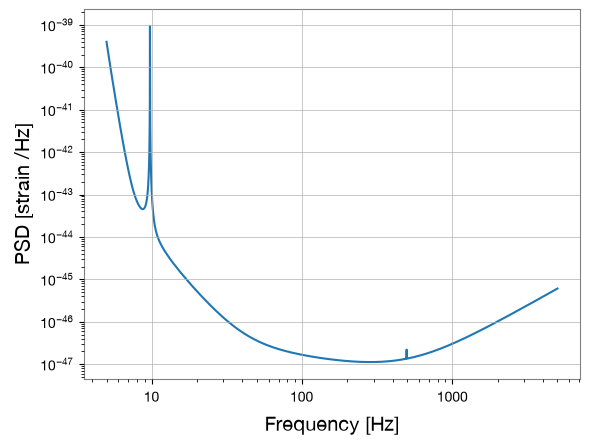

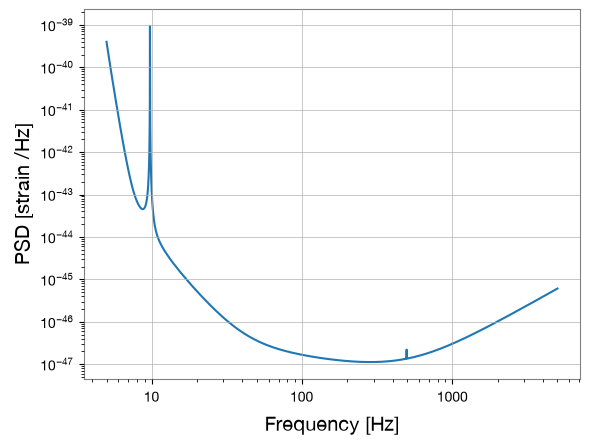

In [9]:
H1_PSD = H1.load_and_set_psd()
L1_PSD = L1.load_and_set_psd()


f = H1.psd.frequencies
psd = H1.psd.values

plt.loglog(f, psd)
plt.xlabel("Frequency [Hz]")
plt.ylabel("PSD [strain /Hz]")

plt.show()


f = L1.psd.frequencies
psd = L1.psd.values

plt.loglog(f, psd)
plt.xlabel("Frequency [Hz]")
plt.ylabel("PSD [strain /Hz]")

plt.show()

L1, H1 exactly same basically. Now generating simulated noise to add on.

In [13]:
key = jax.random.key(0)
key_H1, key_L1 = jax.random.split(key)

for detector, key in [(H1, key_H1), (L1, key_L1)]:
    detector.simulate_and_set_noise(
        duration=4.0,
        sampling_frequency=2048.0,
        trigger_time=0.0,
        f_min=20.0,
        f_max=1024,
        rng_key=key,
        post_trigger_duration=2.0,
    )

noise_H1 = H1.data.fd
noise_L1 = L1.data.fd

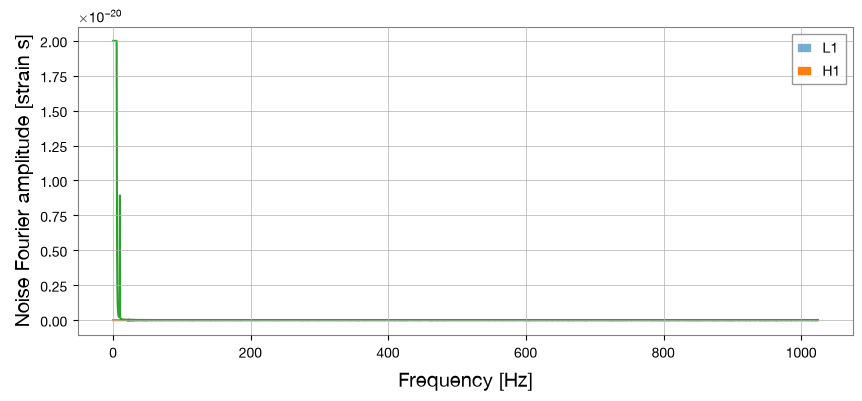

In [25]:
plt.figure(figsize=(10, 4))

plt.plot(L1.data.frequencies, jnp.real(noise_L1), label="L1", alpha=0.6)
plt.plot(H1.data.frequencies, jnp.real(noise_H1), label="H1") # why are there some gaps in the data?
plt.plot(f, jnp.sqrt(psd)/(4*df))
plt.xlabel("Frequency [Hz]")
plt.ylabel("Noise Fourier amplitude [strain s]")
plt.legend()
plt.show()

Is this correct way to check proper noise?

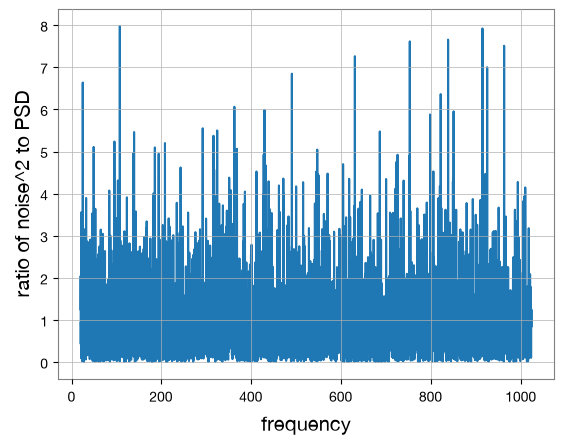

H1 Mean ratio: 0.9825248181370849


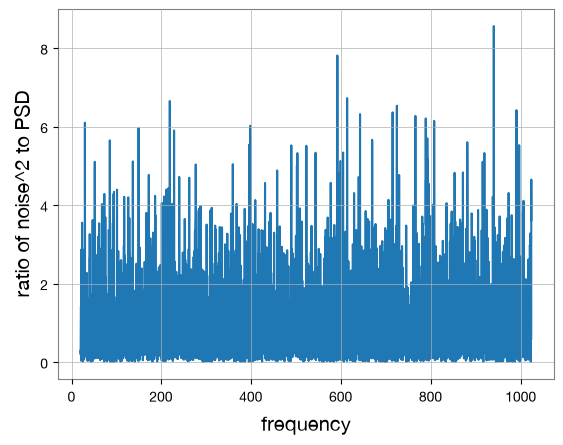

L1 Mean ratio: 1.0189307871876152


In [17]:
df = 0.25

for detector in [H1, L1]:
    f = detector.data.frequencies
    noise = detector.data.fd
    psd = detector.psd.values

    # Only examine the simulated noise band
    mask = (f >= 20) & (f <= 1023.75)

    ratio = 2 * df * jnp.abs(noise[mask])**2 / psd[mask]
    plt.plot(f[mask], ratio)
    plt.xlabel("frequency")
    plt.ylabel("ratio of noise^2 to PSD")
    plt.show()
    
    print(detector.name, "Mean ratio:", jnp.mean(ratio))

Now add noise to the waveforms at H1 and L1

In [22]:
detect_H1 = h_to_htime_shift(h_H1, df, N, shift = 2, noise = H1.data.fd)
detect_L1 = h_to_htime_shift(h_L1, df, N, shift = 2, noise = L1.data.fd)

clean_H1 = h_to_htime_shift(h_H1, df, N, shift = 2)
clean_L1 = h_to_htime_shift(h_L1, df, N, shift = 2)

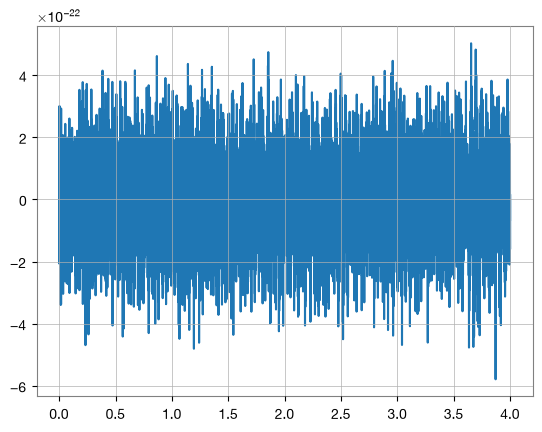

In [23]:
plt.plot(time, H1.data.td)

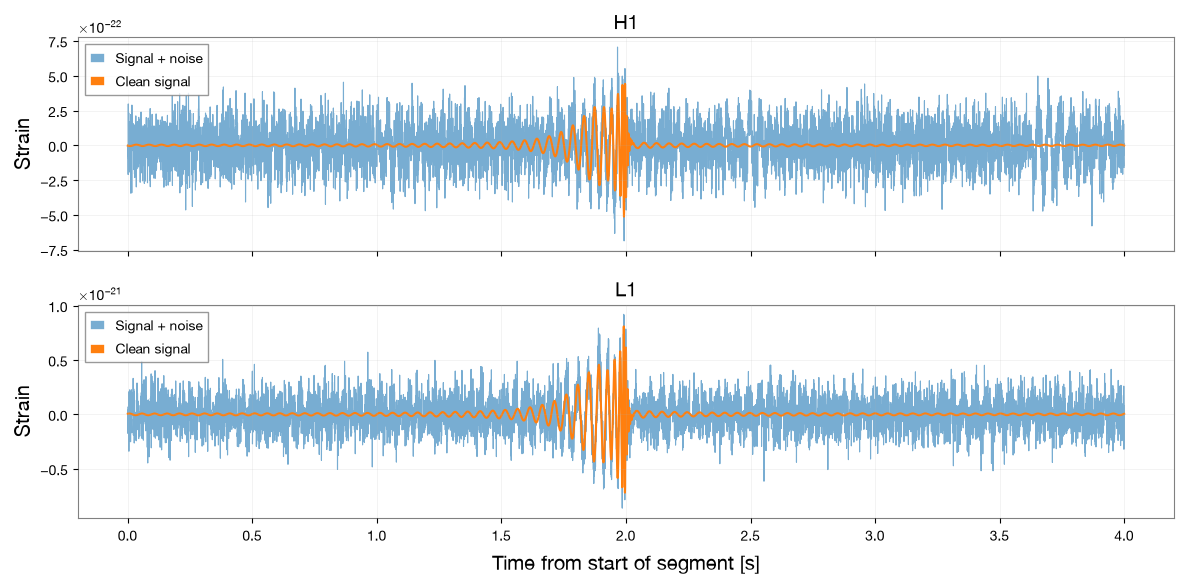

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, detector, clean, noisy in [
    (axes[0], "H1", clean_H1, detect_H1),
    (axes[1], "L1", clean_L1, detect_L1),
]:
    ax.plot(time, noisy, color="tab:blue", alpha=0.6,
            linewidth=0.8, label="Signal + noise")
    ax.plot(time, clean, color="tab:orange",
            linewidth=1.5, label="Clean signal")
    ax.set_title(detector)
    ax.set_ylabel("Strain")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time from start of segment [s]")

fig.tight_layout()
plt.show()

In [26]:

def log_likelihood(data_fd, model_fd, psd, df):
    residual = data_fd - model_fd
    return -2.0 * df * jnp.sum(jnp.abs(residual)**2 / psd)


# Select the same frequencies used to generate the waveform.
f_noise = H1.data.frequencies
in_band = (f_noise >= frequency[0]) & (f_noise <= frequency[-1])

f = f_noise[in_band]
noise_fd = H1.data.fd[in_band]

psd = jnp.interp(f, H1.psd.frequencies, H1.psd.values)

logL_noise = log_likelihood(noise_fd, jnp.zeros_like(noise_fd), psd, df)

print(f"Number of bins: {f.size}")
print(f"Noise-only log likelihood: {float(logL_noise):.2f}")
print(f"-logL / number of bins: {float(-logL_noise / f.size):.3f}")

Number of bins: 4016
Noise-only log likelihood: -3945.82
-logL / number of bins: 0.983


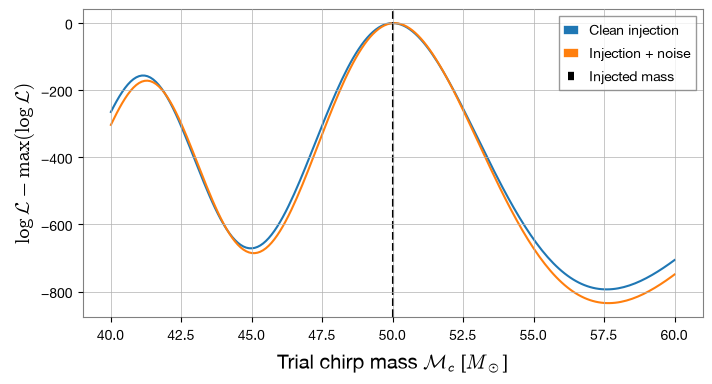

Clean peak: 50.00 solar masses
Noisy peak: 50.10 solar masses


In [27]:
injected_mass = params["M_c"]  # 50 in your notebook
trial_masses = jnp.linspace(injected_mass - 10, injected_mass + 10, 201)

# Use the same 2-second shift for the injection and all trial waveforms.
time_shift = jnp.exp(-2j * jnp.pi * f * 2.0)

# Construct the two datasets once, before varying the trial mass.
data_clean_fd = h_H1 * time_shift
data_noisy_fd = data_clean_fd + noise_fd

@jax.jit
def trial_h1_waveform(chirp_mass):
    trial_params = {**params, "M_c": chirp_mass}
    pols = waveform(f, trial_params)

    h_trial = F_H1["p"] * pols["p"] + F_H1["c"] * pols["c"]
    return h_trial * time_shift


logL_clean = []
logL_noisy = []

for mass in trial_masses:
    model_fd = trial_h1_waveform(mass)
    logL_clean.append(log_likelihood(data_clean_fd, model_fd, psd, df))
    logL_noisy.append(log_likelihood(data_noisy_fd, model_fd, psd, df))

logL_clean = jnp.array(logL_clean)
logL_noisy = jnp.array(logL_noisy)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trial_masses, logL_clean - logL_clean.max(), label="Clean injection")
ax.plot(trial_masses, logL_noisy - logL_noisy.max(), label="Injection + noise")
ax.axvline(injected_mass, color="black", linestyle="--", label="Injected mass")
ax.set_xlabel(r"Trial chirp mass $\mathcal{M}_c$ [$M_\odot$]")
ax.set_ylabel(r"$\log \mathcal{L} - \max(\log \mathcal{L})$")
ax.legend()
plt.show()

print(f"Clean peak: {float(trial_masses[jnp.argmax(logL_clean)]):.2f} solar masses")
print(f"Noisy peak: {float(trial_masses[jnp.argmax(logL_noisy)]):.2f} solar masses")

### Now with geocenter time difference added: (22nd Nov)

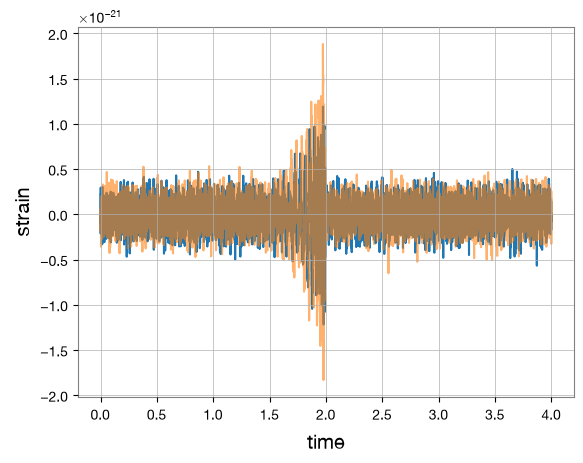

In [28]:
response_params = {
    "ra": source_params["ra"],
    "dec": source_params["dec"],
    "psi": source_params["psi"],
    "t_c": 0.0,  # Geocentric merger time relative to the trigger, in seconds
}

h_H1_fd = H1.fd_response(frequency, polarizations, response_params)
h_L1_fd = L1.fd_response(frequency, polarizations, response_params)

# Your helper now just pads the frequency grid and converts to time.
h_H1_time = h_to_htime_shift(h_H1_fd, df, N, shift=0.0, noise = H1.data.fd)
h_L1_time = h_to_htime_shift(h_L1_fd, df, N, shift=0.0, noise = L1.data.fd)


plt.plot(time, h_H1_time)
plt.plot(time, h_L1_time, alpha =0.6)
plt.xlabel("time")
plt.ylabel("strain")

plt.show()

In [29]:
# A second binary with a different chirp mass.
params_2 = {**params, "M_c": 30.0}
polarizations_2 = waveform(frequency, params_2)

# A different sky position and a geocentric merger 40 ms after the trigger.
response_params_2 = {**response_params, "ra": 2.0, "dec": -0.3, "t_c": 0.2}

H1_1_fd = H1.fd_response(frequency, polarizations, response_params)
H1_2_fd = H1.fd_response(frequency, polarizations_2, response_params_2)
L1_1_fd = L1.fd_response(frequency, polarizations, response_params)
L1_2_fd = L1.fd_response(frequency, polarizations_2, response_params_2)

total_H1_fd = H1_1_fd + H1_2_fd
total_L1_fd = L1_1_fd + L1_2_fd

detected_H1 = h_to_htime_shift(total_H1_fd, df, N, shift= 0, noise = H1.data.fd)
detected_L1 = h_to_htime_shift(total_L1_fd, df, N, shift= 0, noise = L1.data.fd)

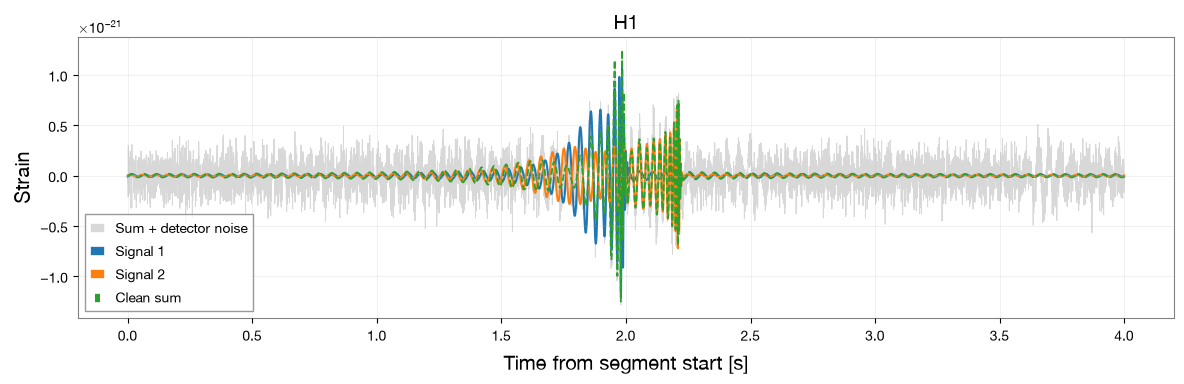

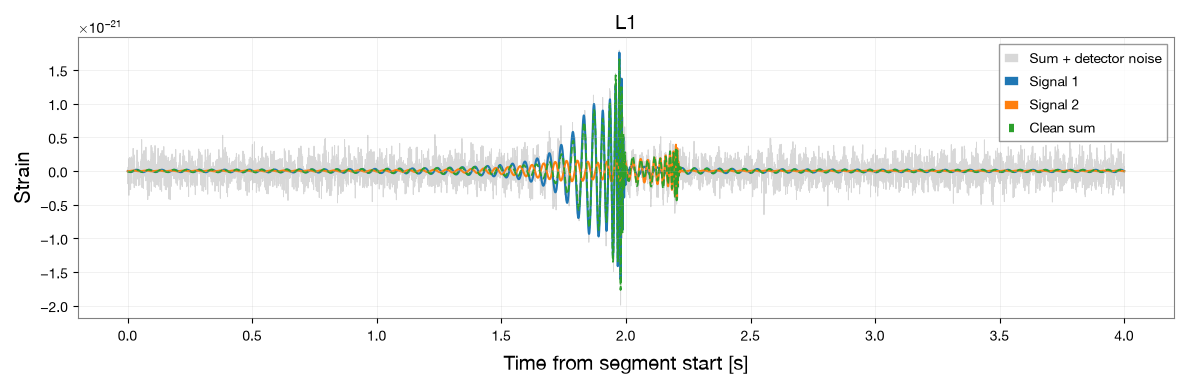

In [30]:
## Now plotting:
for name, signal_1_fd, signal_2_fd, total_fd, noisy_td in [
    ("H1", H1_1_fd, H1_2_fd, total_H1_fd, detected_H1),
    ("L1", L1_1_fd, L1_2_fd, total_L1_fd, detected_L1),
]:
    signal_1_td = h_to_htime_shift(signal_1_fd, df, N, shift=0)
    signal_2_td = h_to_htime_shift(signal_2_fd, df, N, shift=0)
    total_td = h_to_htime_shift(total_fd, df, N, shift=0)

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(time, noisy_td, color="0.5", alpha=0.3,
            linewidth=0.7, label="Sum + detector noise")
    ax.plot(time, signal_1_td, color="tab:blue", label="Signal 1")
    ax.plot(time, signal_2_td, color="tab:orange", label="Signal 2")
    ax.plot(time, total_td, color="tab:green", linestyle="--",
            linewidth=1.3, label="Clean sum")

    ax.set_title(name)
    ax.set_xlabel("Time from segment start [s]")

    ax.set_ylabel("Strain")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

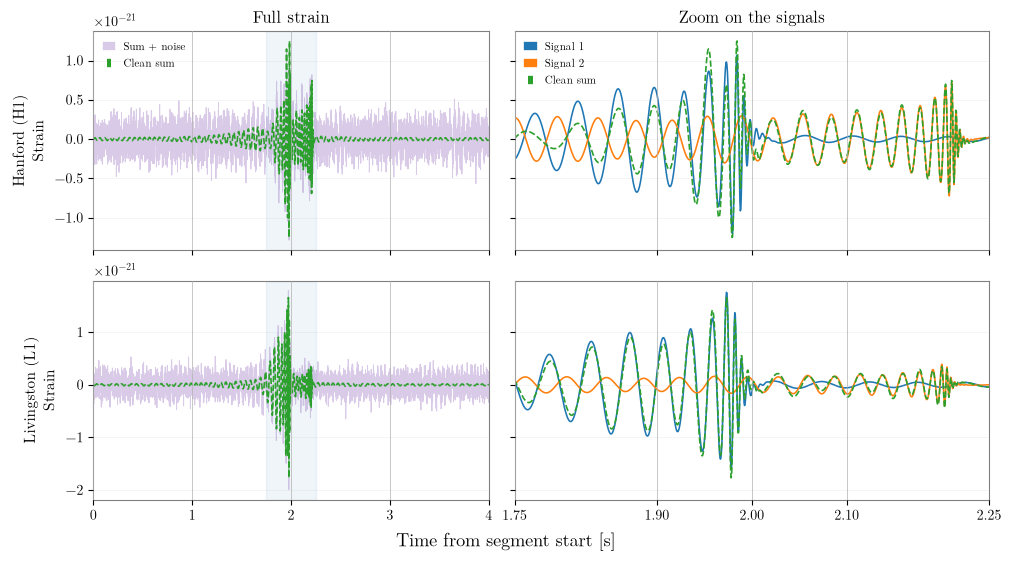

In [40]:
zoom_start, zoom_end = 1.75, 2.25

plt.rcParams.update({
    "font.family": "Latin Modern Roman",
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 5.5),
    sharex="col",
    sharey="row",
    gridspec_kw={"width_ratios": [1, 1.2]},
    layout="constrained",
)

detectors = [
    ("Hanford (H1)", H1_1_fd, H1_2_fd, total_H1_fd, detected_H1),
    ("Livingston (L1)", L1_1_fd, L1_2_fd, total_L1_fd, detected_L1),
]

for (full_ax, zoom_ax), (name, signal_1_fd, signal_2_fd, total_fd, noisy_td) in zip(
    axes, detectors
):
    signal_1_td = h_to_htime_shift(signal_1_fd, df, N, shift=0)
    signal_2_td = h_to_htime_shift(signal_2_fd, df, N, shift=0)
    total_td = h_to_htime_shift(total_fd, df, N, shift=0)

    full_ax.axvspan(zoom_start, zoom_end, color="tab:blue", alpha=0.07)
    full_ax.plot(time, noisy_td, color="tab:purple", alpha=0.35,
                lw=0.65, label="Sum + noise")
    full_ax.plot(time, total_td, color="tab:green", ls="--",
                lw=1.2, label="Clean sum")

    zoom_ax.plot(time, signal_1_td, color="tab:blue", lw=1.15, label="Signal 1")
    zoom_ax.plot(time, signal_2_td, color="tab:orange", lw=1.15, label="Signal 2")
    zoom_ax.plot(time, total_td, color="tab:green", ls="--", lw=1.2, label="Clean sum")

    full_ax.set_ylabel(f"{name}\nStrain")
    for ax in (full_ax, zoom_ax):
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
        ax.grid(axis="y", alpha=0.18)

axes[0, 0].set_title("Full strain")
axes[0, 1].set_title("Zoom on the signals")

axes[1, 0].set_xlim(0, N * dt)
axes[1, 0].set_xticks([0, 1, 2, 3, 4])
axes[1, 1].set_xlim(zoom_start, zoom_end)
axes[1, 1].set_xticks([1.75, 1.9, 2.0,2.1,2.25])
fig.supxlabel("Time from segment start [s]")

axes[0, 0].legend(loc="upper left", frameon=False, fontsize=8)
axes[0, 1].legend(loc="upper left", frameon=False, fontsize=8)

fig.savefig("overlapping_detector_strain.pdf", bbox_inches="tight")
plt.show()

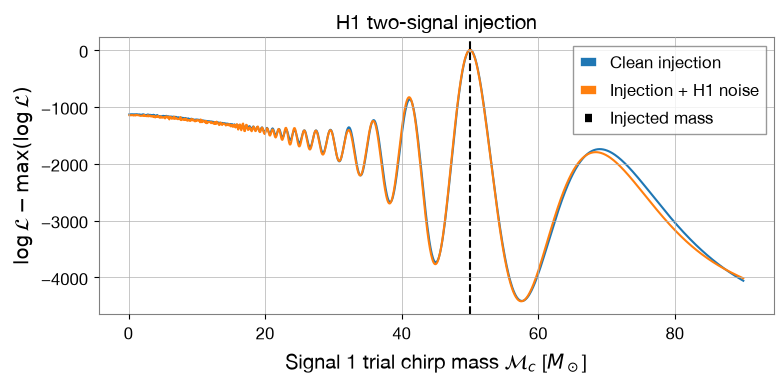

H1 clean peak: 50.044 solar masses
H1 noisy peak: 49.954 solar masses


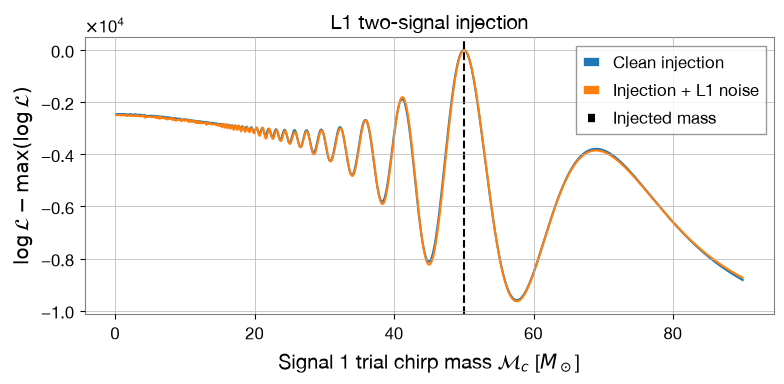

L1 clean peak: 50.044 solar masses
L1 noisy peak: 50.044 solar masses


In [ ]:
injected_mass = params["M_c"]
trial_masses = jnp.linspace(injected_mass - 49.9, injected_mass + 40, 1000)

log_like_for_both = jnp.zeros_like(trial_masses)
for name, detector, total_fd, signal_2_fd in [("H1", H1, total_H1_fd, H1_2_fd),("L1", L1, total_L1_fd, L1_2_fd)]:
    # Select detector noise bins that match the waveform grid.
    noise_frequencies = detector.data.frequencies
    in_band = ((noise_frequencies >= frequency[0]) & (noise_frequencies <= frequency[-1]))
    assert jnp.array_equal(noise_frequencies[in_band], frequency), ( f"{name} noise and waveform frequency grids must match.")

    noise_in_band = detector.data.fd[in_band]
    psd = detector.psd.values[in_band]

    # Keep the data and noise fixed across the mass scan.
    data_clean_fd = total_fd
    data_noisy_fd = total_fd + noise_in_band

    @jax.jit
    def likelihoods_at_mass(mass):
        trial_params = {**params, "M_c": mass}
        trial_pols = waveform(frequency, trial_params)
        trial_signal_1_fd = detector.fd_response(frequency, trial_pols, response_params)
        model_fd = trial_signal_1_fd + signal_2_fd

        clean = log_likelihood(data_clean_fd, model_fd, psd, df)
        noisy = log_likelihood(data_noisy_fd, model_fd, psd, df)
        return clean, noisy

    logL_clean = []
    logL_noisy = []
    
    for mass in trial_masses:
        clean, noisy = likelihoods_at_mass(mass)
        logL_clean.append(clean)
        logL_noisy.append(noisy)

    
    
    logL_clean = jnp.array(logL_clean)
    logL_noisy = jnp.array(logL_noisy)
    log_like_for_both += logL_noisy

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(trial_masses, logL_clean - logL_clean.max(), label="Clean injection")
    ax.plot(trial_masses, logL_noisy - logL_noisy.max(), label=f"Injection + {name} noise")
    ax.axvline(injected_mass, color="black", linestyle="--", label="Injected mass")
    ax.set_xlabel(r"Signal 1 trial chirp mass $\mathcal{M}_c$ [$M_\odot$]")
    ax.set_ylabel(r"$\log \mathcal{L} - \max(\log \mathcal{L})$")
    ax.set_title(f"{name} two-signal injection")
    ax.legend()
    fig.tight_layout()
    plt.show()

    clean_peak = trial_masses[jnp.argmax(logL_clean)]
    noisy_peak = trial_masses[jnp.argmax(logL_noisy)]
    print(f"{name} clean peak: {float(clean_peak):.3f} solar masses")
    print(f"{name} noisy peak: {float(noisy_peak):.3f} solar masses")

Now using likelihood of both H1 and L1 together

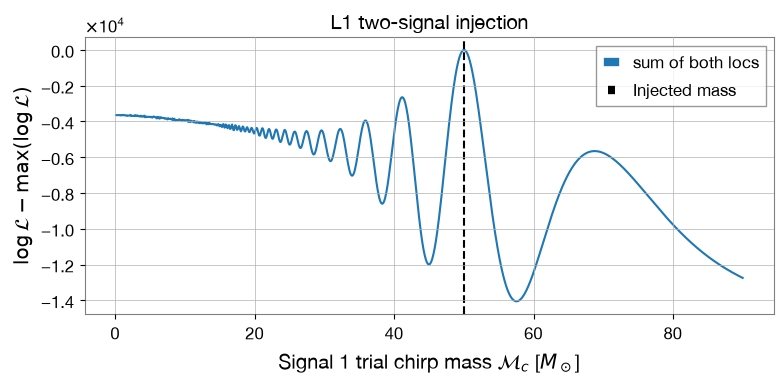

L1 peak: 50.044 solar masses


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trial_masses, log_like_for_both - log_like_for_both.max(), label="sum of both locs")
ax.axvline(injected_mass, color="black", linestyle="--", label="Injected mass")
ax.set_xlabel(r"Signal 1 trial chirp mass $\mathcal{M}_c$ [$M_\odot$]")
ax.set_ylabel(r"$\log \mathcal{L} - \max(\log \mathcal{L})$")
ax.set_title(f"{name} two-signal injection")
ax.legend()
fig.tight_layout()
plt.show()
peak = trial_masses[jnp.argmax(log_like_for_both)]
print(f"{name} peak: {float(peak):.3f} solar masses")


Clean H1 injection: (50.000, 30.000) solar masses
H1 injection with noise: (49.960, 30.000) solar masses


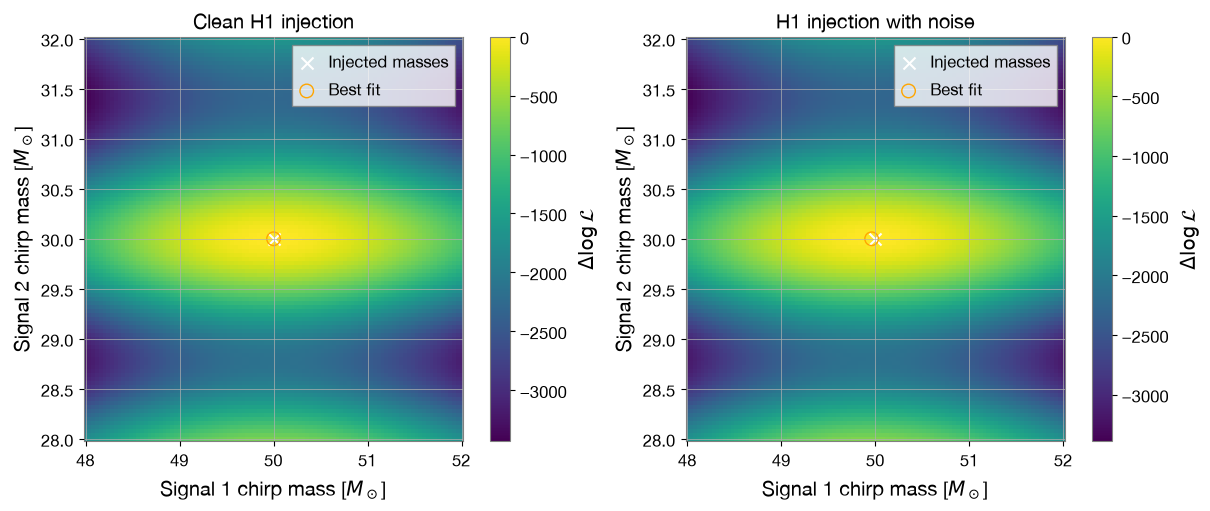

In [ ]:
injected_mass_1 = params["M_c"]
injected_mass_2 = params_2["M_c"]

masses_1 = jnp.linspace(injected_mass_1 - 2, injected_mass_1 + 2, 101)
masses_2 = jnp.linspace(injected_mass_2 - 2, injected_mass_2 + 2, 101)

# Set up the clean and noisy H1 data on the waveform grid.
f_H1 = H1.data.frequencies
in_band = (f_H1 >= frequency[0]) & (f_H1 <= frequency[-1])
assert jnp.array_equal(f_H1[in_band], frequency)
assert jnp.array_equal(f_H1, H1.psd.frequencies)

psd_H1 = H1.psd.values[in_band]
data_clean = total_H1_fd
data_noisy = data_clean + H1.data.fd[in_band]


def projected_waveform(mass, source_params, projection_params):
    trial_params = {**source_params, "M_c": mass}
    pols = waveform(frequency, trial_params)
    return H1.fd_response(frequency, pols, projection_params)


make_waveforms = jax.jit(
    jax.vmap(projected_waveform, in_axes=(0, None, None))
)
waveforms_1 = make_waveforms(masses_1, params, response_params)
waveforms_2 = make_waveforms(masses_2, params_2, response_params_2)


@jax.jit
def likelihood_row(h2):
    # Hold mass 2 fixed for this row and try every mass 1.
    models = waveforms_1 + h2

    clean = jax.vmap(lambda h: log_likelihood(data_clean, h, psd_H1, df))(models)
    noisy = jax.vmap(lambda h: log_likelihood(data_noisy, h, psd_H1, df))(models)
    return clean, noisy


rows = [likelihood_row(h2) for h2 in waveforms_2]
clean_grid = jnp.stack([clean for clean, noisy in rows])
noisy_grid = jnp.stack([noisy for clean, noisy in rows])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, title, grid in zip(
    axes, ["Clean H1 injection", "H1 injection with noise"], [clean_grid, noisy_grid]
):
    i2, i1 = jnp.unravel_index(jnp.argmax(grid), grid.shape)
    best_mass_1 = float(masses_1[i1])
    best_mass_2 = float(masses_2[i2])

    image = ax.pcolormesh(
        masses_1, masses_2, grid - grid.max(), shading="auto", cmap="viridis"
    )
    fig.colorbar(image, ax=ax, label=r"$\Delta\log\mathcal{L}$")
    ax.scatter(injected_mass_1, injected_mass_2, marker="x",
               color="white", s=75, label="Injected masses")
    ax.scatter(best_mass_1, best_mass_2, marker="o", facecolors="none",
               edgecolors="orange", s=95, label="Best fit")
    ax.set(xlabel=r"Signal 1 chirp mass [$M_\odot$]",
           ylabel=r"Signal 2 chirp mass [$M_\odot$]", title=title)
    ax.legend()

    print(f"{title}: ({best_mass_1:.3f}, {best_mass_2:.3f}) solar masses")

plt.show()